# testing CNN model

In [9]:
import numpy as np    
import torch
import torch.nn as nn
import cv2
import matplotlib.pyplot as plt

In [2]:
device =""
if torch.mps.is_available():
    device ='mps'
elif torch.cuda.is_available():
    device='cuda'
else:
    device='cpu'

print(f"selected device is {device}")


selected device is cuda


## define model

In [3]:
# create model by adding required layers
# Input for CNN will bee 64 img 28*28 pixel in single batch
# at a time CNN recive img of 1*28*28 pixel
# Input shape is 1*28*28

# The maxPool2D will reduce feature map  form 32 to 7
# 32 // 2 = 16 - 2 = 14 / 2 = 7 

# padding adding extra zeros on boundries to get edges or border values.

model = nn.Sequential(
    # add convolution 2D layer
    # in_channels = 1    : at time 1 img fed to cnn for processing
    # out_channnels = 16 : no. of feature to be extracted(Behind seen cnn will create 16 no. of kernels, each of 3*3 size)
    # kernel_size = 3    : kernel of 3*3 size
    # padding = 1        : to add padding all border to get border also
    # strid = 1         : at a time move to right side by 1 col and down by 1 row
    nn.Conv2d(in_channels=1,out_channels=16,kernel_size=3,padding=1,stride=1),

    # add reLU
    nn.ReLU(),

    # add max Pooling layer
    nn.MaxPool2d(kernel_size=2,stride=2),

    # add more convolution layer
    # convert img to feature map
    # out_feture no. of neuron in hidden layer 
    nn.Conv2d(in_channels=16,out_channels=32,kernel_size=3,padding=1,stride=1),

    # add reLU
    nn.ReLU(),

    # add 1 more max Pooling layer
    nn.MaxPool2d(kernel_size=2,stride=2),

    # flatten layer
    nn.Flatten(),

    #add final hidden layer with 128 neuron
    # we get 7 value perfeature map
    nn.Linear(in_features=32*7*7,out_features=128),

    #add ReLU on hidden layer
    nn.ReLU(),

    # output layer
    # since threer are 10 digit o/p layer have 10 neuron
    nn.Linear(in_features=128,out_features=10)

)

In [4]:
# move mode to device
model = model.to(device)

## loading parametr into models

In [5]:
model.load_state_dict(torch.load('./mnist_model.pth'))

<All keys matched successfully>

## disable the learning parameters using enabling eval mode

In [6]:
model.eval()

Sequential(
  (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=1568, out_features=128, bias=True)
  (8): ReLU()
  (9): Linear(in_features=128, out_features=10, bias=True)
)

## load img

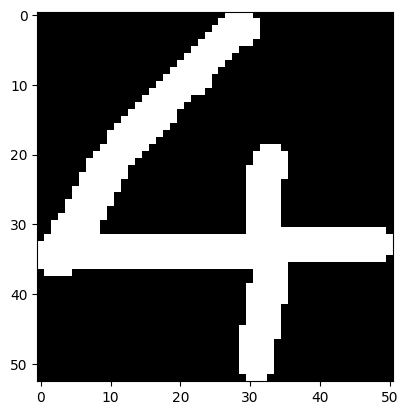

In [ ]:
img = cv2.imread('./test.png')
plt.imshow(img)

## prerpocess img


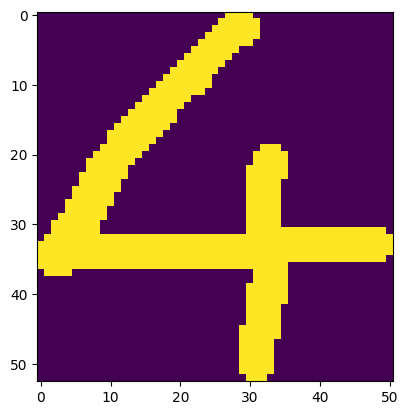

In [13]:
# convert img to grgeyscale
img_grey = cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
plt.imshow(img_grey)

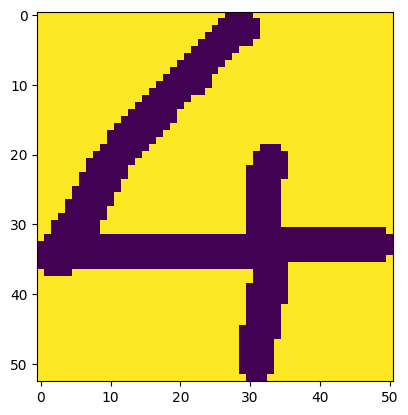

In [15]:
# convert to biinary 
return_value,binary_img = cv2.threshold(img_grey,150,255,cv2.THRESH_BINARY_INV)
plt.imshow(binary_img)

## extract only digit from img

In [18]:
# find location oof digit inside img
point = cv2.findNonZero(binary_img)
print(point)



[[ 0  0]
 [ 1  0]
 [ 2  0]
 ...
 [48 52]
 [49 52]
 [50 52]]


In [21]:
# find the bounding rect from img
x,y,w,h = cv2.boundingRect(point)

# extract digit
digit = binary_img[y:y+h, x:x+w]
print(digit)

cv2.imwrite('test_digit2.png',digit)

[[255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]
 ...
 [255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]]


True

### convert img 28x28 by mvoing digit to center

In [22]:
# get size 
size = max(w,h)

In [26]:
# make squre of size by size
sequre = np.zeros((size,size),dtype=np.uint8)

# find x and y offset 
x_offset = (size-w) //2
y_offset = (size- h ) //2

In [30]:
# put digit in center part if img
sequre[y_offset:y_offset +h, x_offset : x_offset + w] = digit

In [31]:
sequre

array([[  0, 255, 255, ..., 255, 255,   0],
       [  0, 255, 255, ..., 255, 255,   0],
       [  0, 255, 255, ..., 255, 255,   0],
       ...,
       [  0, 255, 255, ..., 255, 255,   0],
       [  0, 255, 255, ..., 255, 255,   0],
       [  0, 255, 255, ..., 255, 255,   0]], shape=(53, 53), dtype=uint8)

True

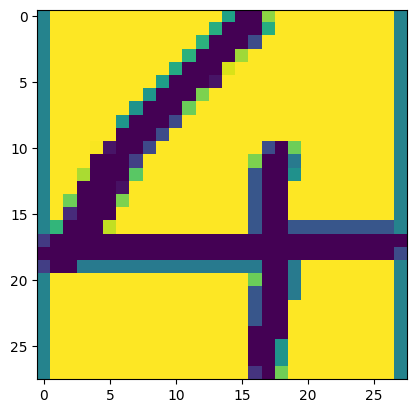

In [34]:
# resize img to match modesl requirement 28*28
img_resized = cv2.resize(sequre,(28,28))
plt.imshow(img_resized)
cv2.imwrite('test_final2.png',img_resized)

In [37]:
from torchvision import transforms
transforms = transforms.ToTensor()

# convert img to tensor 
img = transforms(img_resized)

# convert 
img = img.unsqueeze(0)

In [38]:
# move img to device
img = img.to(device)

In [ ]:
# get class by passing img to model
with torch.no_grad():
    # pass img to model 
    output = model(img)
    print(output)

    # find actual class
    predition = torch.argmax(output,dim=1)
    print(f"finlclass = {predition}")
    

tensor([[-11.7833,  -1.2866,  -5.3782,   1.6324,  -0.3237,   1.0053,   1.8702,
          -8.7772,  -2.4190,   2.1786]], device='cuda:0')
finl class = tensor([9], device='cuda:0')


In [ ]:
# opencv contour() detection
# for img contain color : 
    # model train on greyscale img 